# kinyarwanda tweet sentiment classification

fine tuning afroxlmr on kinyarwanda tweets and testing it against tfidf baselines

## 0 setup

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/mbonikevin/senti-kinyarwanda.git"
REPO_DIR = "senti-kinyarwanda"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(REPO_DIR)

    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers>=4.40,<5", "accelerate>=0.30", "datasets>=2.18",
                    "sentencepiece", "protobuf"], check=True)

sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /content/senti-kinyarwanda


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

from src.data import load_splits, describe, save_processed, ID_TO_LABEL, LABEL_ORDER
from src.metrics import compute_metrics, format_metrics_report, save_metrics, plot_confusion_matrix, comparison_table
from src import viz, leakage
print("label mapping:", ID_TO_LABEL)

label mapping: {0: 'positive', 1: 'neutral', 2: 'negative'}


## 1 data

the kinyarwanda subset of afrisenti muhammad et al 2023 read from the official repo

In [3]:
splits = load_splits() # light cleaning the urls > <url> whitespace
save_processed(splits)
describe(splits)

  train: 3302 tweets
  validation: 827 tweets
  test: 1026 tweets


,split,n,mean_tokens,median_tokens,p95_tokens,max_tokens,n_positive,pct_positive,n_neutral,pct_neutral,n_negative,pct_negative
0,train,3302,14.9,15,24,69,899,27.2,1257,38.1,1146,34.7
1,validation,827,14.7,14,24,43,225,27.2,315,38.1,287,34.7
2,test,1026,15.0,15,24,65,278,27.1,393,38.3,355,34.6


### 1.1 does the official split leak?

In [4]:
print(leakage.overlap_report(splits).to_string(index=False))
print()
print("accuracy ceiling implied by contradictory duplicates:",
      leakage.annotation_ceiling(splits, "test"))

contra = leakage.contradictory_examples(splits, "train", "test")
print(f"\n{len(contra)} tweets appear verbatim in train and test with different gold labels:")
contra.head(10)

   split_a    split_b  shared_texts  contradictory_labels  pct_of_b
     train validation            32                     7      3.87
     train       test            27                     7      2.63
validation       test             8                     1      0.78

accuracy ceiling implied by contradictory duplicates: {'split': 'test', 'n': 1026, 'contradictory_rows': 7, 'accuracy_ceiling': 0.9932}

7 tweets appear verbatim in train and test with different gold labels:


,text,label_in_train,label_in_test
0,@user Pizza ngew ukunda kunsema sinkunda kuyirya cyane kugirango nirinde iby...,positive,negative
1,"Ba Nyiribikamyo: Banyonzi, Birabujijwe gufata ku modoka Kuko biteza impanuka...",neutral,negative
2,Binanze mwegere umuhe undi munsi kuko birashoboka ko igihe wamuhaye byanze. ...,neutral,positive
3,@user @user Mwiriwe neza None c ? Kubera iki? Umurongo wo kwiyandikisha Mwaw...,negative,neutral
4,"@user aratabaza kuri uyu munsi w'intwari, kuko ari gukorerwa akarengane (iho...",positive,negative
5,Dr. Ugirashebuja Emmanuel yagizwe minisitiri w’ubutabera akaba n’intumwa nku...,positive,neutral
6,@user Bisaba impinduka mu myumvire y'abaturage muri rusange n'abayobozi en p...,neutral,positive


### 1.2 figures for the report

saved reports/figures/class_distribution.png
saved reports/figures/length_distribution.png


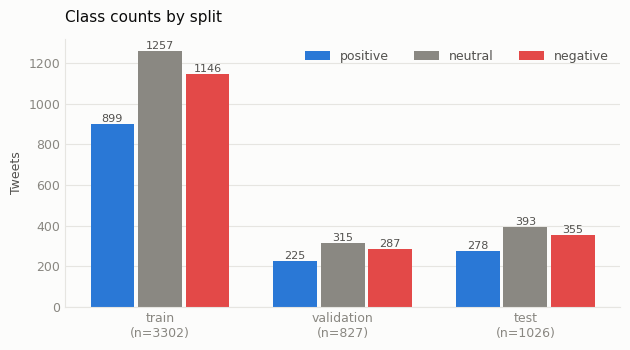

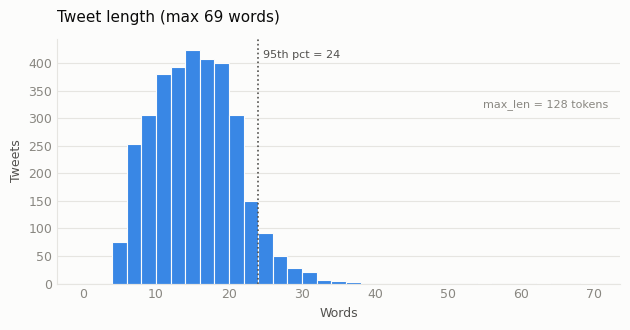

In [5]:
viz.class_distribution(splits)
viz.length_distribution(splits, max_len=128)
plt.show()

## 2 how the tokenizers segment kinyarwanda

an africa adapted model is supposed to split the language better that is easy to
check so check it before leaning on it

In [6]:
from src.tokenizer_analysis import fertility_table, segmentation_examples

print(fertility_table(splits["train"]["text"].tolist(), max_len=128).to_string(index=False))
print()
print(segmentation_examples().to_string(index=False))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/729 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/1.55M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


       tokenizer  vocab_size  subwords_per_word  median_len  p95_len  max_len_seen  pct_truncated_at_128
  afro-xlmr-base      250002               2.68          39       68           155                  0.06
xlm-roberta-base      250002               2.68          39       68           155                  0.06
  afriberta_base       70006               2.40          34       64           196                  0.09

           word  n_subwords                    segmentation
   Abanyarwanda           4          ▁Aba | nya | rwa | nda
   ntabyihogoza           6    ▁ | nta | by | ih | og | oza
    byagutabara           4           ▁by | agu | ta | bara
isobanurampamvu           6 ▁iso | ban | ura | mpa | m | vu
      umuryango           3                ▁umur | yang | o
           good           1                           ▁good


## 3 baselines

the majority class one shows what doing nothing scores the tfidf logistic
regression one is what the transformer has to beat

In [7]:
from src.baseline import BASELINES, run_baseline, top_features

fitted, baseline_val = {}, {}
for name in BASELINES:
    model, m, secs = run_baseline(name, splits, eval_split="validation")
    fitted[name], baseline_val[name] = model, m
    print(format_metrics_report(m, name), f"\n  fit: {secs:.2f}s\n")

Model: Majority class
  Macro F1        : 0.1839
  Macro precision : 0.1270
  Macro recall    : 0.3333
  Weighted F1     : 0.2101
  Accuracy        : 0.3809

Per class:
  positive   precision=0.000  recall=0.000  f1=0.000  support=225
  neutral    precision=0.381  recall=1.000  f1=0.552  support=315
  negative   precision=0.000  recall=0.000  f1=0.000  support=287 
  fit: 0.00s

Model: TF-IDF + NaiveBayes
  Macro F1        : 0.5706
  Macro precision : 0.6282
  Macro recall    : 0.5639
  Weighted F1     : 0.5758
  Accuracy        : 0.5816

Per class:
  positive   precision=0.777  recall=0.387  f1=0.516  support=225
  neutral    precision=0.534  recall=0.695  f1=0.604  support=315
  negative   precision=0.574  recall=0.610  f1=0.591  support=287 
  fit: 0.13s

Model: TF-IDF + LogReg
  Macro F1        : 0.6206
  Macro precision : 0.6229
  Macro recall    : 0.6189
  Weighted F1     : 0.6193
  Accuracy        : 0.6191

Per class:
  positive   precision=0.654  recall=0.613  f1=0.633  support

In [8]:
# shows the model learned real kinyarwanda sentiment words
for label, feats in top_features(fitted["TF-IDF + LogReg"], n=10).items():
    print(f"{label:9s}: {', '.join(w for w, _ in feats)}")

positive : mwiza, neza, nziza, amahoro, cyane, humura, imana, uwiteka, rwanda, ibyiza
neutral  : iki, na, ese, gukora, wa, ya, user aho, ba, nari, imwe
negative : ngo, cg, ari, nabi, ko, ibaze, mubi, ubusa, umunwa, user ikibazo


## 4 baseline test scores

nothing here was tuned the baselines use their library defaults so scoring them on
the test set once cannot bend any choice made later

In [9]:
for name in BASELINES:
    model, m, _ = run_baseline(name, splits, eval_split="test")
    save_metrics(m, name, "test")
    print(f"{name:24s} macro-F1 {m['macro_f1']:.4f}  weighted-F1 {m['weighted_f1']:.4f}  acc {m['accuracy']:.4f}")

BASELINE_VAL_F1 = baseline_val["TF-IDF + LogReg"]["macro_f1"]
print(f"\nbar to beat on validation: macro-F1 {BASELINE_VAL_F1:.4f}")

Majority class           macro-F1 0.1846  weighted-F1 0.2122  acc 0.3830
TF-IDF + NaiveBayes      macro-F1 0.5511  weighted-F1 0.5532  acc 0.5556
TF-IDF + LogReg          macro-F1 0.6017  weighted-F1 0.5981  acc 0.5984

bar to beat on validation: macro-F1 0.6206


## 5 transformer experiments  *gpu required*

each run states its hypothesis first and then goes in `reports/results/experiments_*.csv`
validation scores only no test set in this section

In [10]:
import torch, transformers
print("transformers:", transformers.__version__)

assert int(transformers.__version__.split(".")[0]) < 5, \
    "needs transformers 4.x re-run the setup cell then Runtime > Restart session"
assert torch.cuda.is_available(), \
    "no gpu Runtime > Change runtime type > T4 GPU then re-run from the top"

print("gpu:", torch.cuda.get_device_name(0))

transformers: 4.57.6
gpu: Tesla T4


In [11]:
from src.train_transformer import TrainConfig, run_experiment, predict, AFRO_XLMR_BASE, XLMR_BASE
from src.experiment_log import reset_log, load_all_experiments

# rerunning this notebook should not duplicate rows in the log
for m in ("afro-xlmr-base", "xlm-roberta-base"):
    reset_log(m)

runs = {}

In [12]:
# experiment 1  the reference configuration
runs["E1"] = run_experiment(
    "E1", TrainConfig(label="E1-afroxlmr-default"), splits,
    change="AfroXLMR-base, lr 2e-5, 3 epochs, max_len 128, batch 16",
    hypothesis="A model with Kinyarwanda in its pretraining beats TF-IDF+LogReg on macro-F1",
    decision="", reason="")


=== E1: afro-xlmr-base lr=2e-05 ep=3 len=128 bs=16 cw=False seed=42 ===
AfroXLMR-base, lr 2e-5, 3 epochs, max_len 128, batch 16


config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at Davlan/afro-xlmr-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,0.842200,0.834875,0.603386,0.599991,0.661565,0.590657,0.599630
2,0.767900,0.772046,0.663845,0.666975,0.671077,0.667074,0.663308
3,0.642400,0.777343,0.681983,0.685396,0.684982,0.685838,0.681915


Map:   0%|          | 0/827 [00:00<?, ? examples/s]

val macro-F1 0.6854 | weighted-F1 0.6819 | acc 0.6820 | 266s


In [13]:
# experiment 2  learning rate two runs one below one above the convention
for lr, tag in [(1e-5, "E2a"), (5e-5, "E2b")]:
    runs[tag] = run_experiment(
        tag, TrainConfig(learning_rate=lr, label=f"{tag}-lr{lr:g}"), splits,
        change=f"learning rate {lr:g} instead of 2e-5",
        hypothesis="2e-5 is the RoBERTa-family convention; 1e-5 may underfit in 3 epochs and 5e-5 may destabilise a 3.3k-example fine-tune",
        decision="", reason="")


=== E2a: afro-xlmr-base lr=1e-05 ep=3 len=128 bs=16 cw=False seed=42 ===
learning rate 1e-05 instead of 2e-5


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at Davlan/afro-xlmr-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,0.859900,0.855677,0.590085,0.572925,0.680590,0.571150,0.574829
2,0.734000,0.797701,0.668682,0.671073,0.685579,0.671978,0.666808
3,0.524500,0.840775,0.666264,0.671077,0.674872,0.669914,0.666493


Map:   0%|          | 0/827 [00:00<?, ? examples/s]

val macro-F1 0.6711 | weighted-F1 0.6665 | acc 0.6663 | 321s


In [16]:
import gc, torch

def free(run):
    """drop the gpu copy once the row is logged the csv keeps the numbers"""
    run.pop("trainer", None)
    run.pop("tokenizer", None)
    gc.collect()
    torch.cuda.empty_cache()

for r in runs.values():
    free(r)
print(f"{torch.cuda.memory_allocated()/1e9:.1f} GB still allocated")

3.7 GB still allocated


In [17]:
# experiment 3  more epochs load_best_model_at_end means a worse final epoch is not kept
# so this measures whether an extra pass finds anything not whether it overfits
runs["E3"] = run_experiment(
    "E3", TrainConfig(epochs=5, label="E3-5epochs"), splits,
    change="5 epochs instead of 3",
    hypothesis="3.3k examples is small; extra epochs will overfit rather than help",
    decision="", reason="")


=== E3: afro-xlmr-base lr=2e-05 ep=5 len=128 bs=16 cw=False seed=42 ===
5 epochs instead of 3


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at Davlan/afro-xlmr-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,0.851000,0.873244,0.575574,0.563119,0.661297,0.556087,0.565602
2,0.769200,0.757763,0.678356,0.681663,0.682735,0.681074,0.678419
3,0.635000,0.804460,0.674728,0.675373,0.677926,0.680490,0.672048
4,0.511000,0.845020,0.673519,0.675931,0.673704,0.679504,0.672898
5,0.413900,0.894298,0.666264,0.668263,0.667167,0.673609,0.665386


Map:   0%|          | 0/827 [00:00<?, ? examples/s]

val macro-F1 0.6817 | weighted-F1 0.6784 | acc 0.6784 | 576s


In [18]:
# experiment 4  shorter sequences section 2 measured that 5% of tweets exceed 64 subwords
runs["E4"] = run_experiment(
    "E4", TrainConfig(max_len=64, label="E4-maxlen64"), splits,
    change="max_len 64 instead of 128",
    hypothesis="Truncating ~5% of tweets costs little and roughly halves training time",
    decision="", reason="")


=== E4: afro-xlmr-base lr=2e-05 ep=3 len=64 bs=16 cw=False seed=42 ===
max_len 64 instead of 128


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at Davlan/afro-xlmr-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,0.858400,0.835260,0.607013,0.600011,0.653872,0.601719,0.597466
2,0.776700,0.814582,0.654172,0.657037,0.660573,0.663802,0.652692
3,0.645300,0.792094,0.659008,0.663109,0.664767,0.662067,0.659281


Map:   0%|          | 0/827 [00:00<?, ? examples/s]

val macro-F1 0.6631 | weighted-F1 0.6593 | acc 0.6590 | 365s


In [21]:
import gc, torch

def free(run):
    """drop the gpu copy once the row is logged the csv keeps the numbers"""
    run.pop("trainer", None)
    run.pop("tokenizer", None)
    gc.collect()
    torch.cuda.empty_cache()

for r in runs.values():
    free(r)
print(f"{torch.cuda.memory_allocated()/1e9:.1f} GB still allocated")

3.7 GB still allocated


In [22]:
# experiment 5  the ablation same everything base model swapped section 2 established the
# two share a vocabulary so this difference is attributable to pretraining alone
runs["E5"] = run_experiment(
    "E5", TrainConfig(model_name=XLMR_BASE, label="E5-xlmr-ablation"), splits,
    change="plain XLM-RoBERTa-base in place of AfroXLMR-base, all else identical",
    hypothesis="AfroXLMR's African-language adaptive pretraining is worth a measurable amount of macro-F1",
    decision="", reason="")


=== E5: xlm-roberta-base lr=2e-05 ep=3 len=128 bs=16 cw=False seed=42 ===
plain XLM-RoBERTa-base in place of AfroXLMR-base, all else identical


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,1.084800,1.057580,0.451028,0.345528,0.309472,0.409369,0.377901
2,0.980700,0.953444,0.532044,0.526388,0.528404,0.526003,0.530400
3,0.929800,0.930502,0.532044,0.521684,0.534684,0.536172,0.519785


Map:   0%|          | 0/827 [00:00<?, ? examples/s]

val macro-F1 0.5264 | weighted-F1 0.5304 | acc 0.5320 | 649s


In [23]:
# experiment 6  preprocessing reloads the data with the heavier cleaning flags on
splits_heavy = load_splits(strip_emoji=True, fix_elongation=True)
runs["E6"] = run_experiment(
    "E6", TrainConfig(label="E6-heavy-cleaning"), splits_heavy,
    change="emoji stripped and elongated characters collapsed",
    hypothesis="Emoji are often the only sentiment marker in a code-mixed tweet, so removing them should LOWER macro-F1",
    decision="", reason="")

  train: 3302 tweets
  validation: 827 tweets
  test: 1026 tweets

=== E6: afro-xlmr-base lr=2e-05 ep=3 len=128 bs=16 cw=False seed=42 ===
emoji stripped and elongated characters collapsed


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at Davlan/afro-xlmr-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,0.839900,0.889855,0.590085,0.569239,0.647921,0.590053,0.565657
2,0.773600,0.807940,0.672310,0.674090,0.671830,0.678549,0.671600
3,0.638900,0.810991,0.661427,0.663199,0.666993,0.660798,0.661617


Map:   0%|          | 0/827 [00:00<?, ? examples/s]

val macro-F1 0.6741 | weighted-F1 0.6716 | acc 0.6723 | 565s


In [24]:
import gc, torch

def free(run):
    """drop the gpu copy once the row is logged the csv keeps the numbers"""
    run.pop("trainer", None)
    run.pop("tokenizer", None)
    gc.collect()
    torch.cuda.empty_cache()

for r in runs.values():
    free(r)
print(f"{torch.cuda.memory_allocated()/1e9:.1f} GB still allocated")

3.7 GB still allocated


In [25]:
# experiment 7  class weighting matching the baseline's class_weight="balanced"
runs["E7"] = run_experiment(
    "E7", TrainConfig(class_weights=True, label="E7-class-weighted"), splits,
    change="inverse-frequency class weights in the cross-entropy loss",
    hypothesis="Up-weighting the smaller positive class raises macro-F1 even if accuracy drops",
    decision="", reason="")


=== E7: afro-xlmr-base lr=2e-05 ep=3 len=128 bs=16 cw=True seed=42 ===
inverse-frequency class weights in the cross-entropy loss


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at Davlan/afro-xlmr-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,0.827000,0.843279,0.632406,0.635103,0.638885,0.638756,0.630523
2,0.792100,0.793375,0.649335,0.652051,0.654914,0.656410,0.647610
3,0.650900,0.792960,0.684401,0.686860,0.684401,0.691114,0.683289


Map:   0%|          | 0/827 [00:00<?, ? examples/s]

val macro-F1 0.6869 | weighted-F1 0.6833 | acc 0.6844 | 576s


### 5.1 the experiment table

,exp_id,stage,change,hypothesis,val_macro_f1,val_weighted_f1,val_accuracy,train_seconds
0,E1,E1-afroxlmr-default,"AfroXLMR-base, lr 2e-5, 3 epochs, max_len 128, batch 16",A model with Kinyarwanda in its pretraining beats TF-IDF+LogReg on macro-F1,0.6854,0.6819,0.6820,266.4
1,E2a,E2a-lr1e-05,learning rate 1e-05 instead of 2e-5,2e-5 is the RoBERTa-family convention; 1e-5 may underfit in 3 epochs and 5e-...,0.6654,0.6643,0.6638,291.8
2,E2b,E2b-lr5e-05,learning rate 5e-05 instead of 2e-5,2e-5 is the RoBERTa-family convention; 1e-5 may underfit in 3 epochs and 5e-...,0.6711,0.6665,0.6663,321.0
3,E3,E3-5epochs,5 epochs instead of 3,3.3k examples is small; extra epochs will overfit rather than help,0.6817,0.6784,0.6784,576.3
4,E4,E4-maxlen64,max_len 64 instead of 128,Truncating ~5% of tweets costs little and roughly halves training time,0.6631,0.6593,0.6590,364.6
5,E6,E6-heavy-cleaning,emoji stripped and elongated characters collapsed,"Emoji are often the only sentiment marker in a code-mixed tweet, so removing...",0.6741,0.6716,0.6723,564.7
6,E7,E7-class-weighted,inverse-frequency class weights in the cross-entropy loss,Up-weighting the smaller positive class raises macro-F1 even if accuracy drops,0.6869,0.6833,0.6844,576.2
7,E5,E5-xlmr-ablation,"plain XLM-RoBERTa-base in place of AfroXLMR-base, all else identical",AfroXLMR's African-language adaptive pretraining is worth a measurable amoun...,0.5264,0.5304,0.5320,648.7


saved reports/figures/experiment_results.png


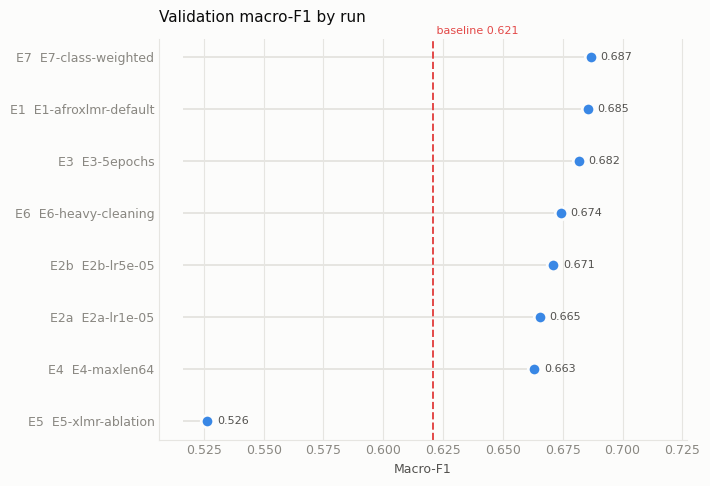


best on validation: E7
Apply the tie rule from src/experiment_log.py before declaring a winner: configurations within 0.01 macro-F1 are tied, and the cheaper one wins.


In [26]:
log = load_all_experiments()
display(log[["exp_id", "stage", "change", "hypothesis", "val_macro_f1", "val_weighted_f1", "val_accuracy", "train_seconds"]])

viz.experiment_results(log, baseline_f1=BASELINE_VAL_F1)
plt.show()

best_id = log.loc[log["val_macro_f1"].idxmax(), "exp_id"]
print(f"\nbest on validation: {best_id}")
print("Apply the tie rule from src/experiment_log.py before declaring a winner: "
      "configurations within 0.01 macro-F1 are tied, and the cheaper one wins.")

## 6 final test evaluation  *run once*

pick the winner by the tie rule above set `BEST` to its key in `runs` and run this
section once nothing after this can change a configuration choice

In [28]:
from src.train_transformer import train

BEST = "E1"   # < set from section 5.1
cfg = runs[BEST]["cfg"]
print("final model:", cfg.summary())

trainer, tokenizer, _ = train(cfg, splits)

test_preds, test_probs = predict(trainer, splits, "test", cfg.max_len, tokenizer)
m_test = compute_metrics(splits["test"]["label"], test_preds)
save_metrics(m_test, f"AfroXLMR ({BEST})", "test")
print(format_metrics_report(m_test, f"AfroXLMR ({BEST})"))

final model: afro-xlmr-base lr=2e-05 ep=3 len=128 bs=16 cw=False seed=42


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at Davlan/afro-xlmr-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/3302 [00:00<?, ? examples/s]

Map:   0%|          | 0/827 [00:00<?, ? examples/s]

Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
1,0.842200,0.834875,0.603386,0.599991,0.661565,0.590657,0.599630
2,0.767900,0.772046,0.663845,0.666975,0.671077,0.667074,0.663308
3,0.642400,0.777343,0.681983,0.685396,0.684982,0.685838,0.681915


Map:   0%|          | 0/1026 [00:00<?, ? examples/s]

Model: AfroXLMR (E1)
  Macro F1        : 0.6841
  Macro precision : 0.6842
  Macro recall    : 0.6842
  Weighted F1     : 0.6802
  Accuracy        : 0.6803

Per class:
  positive   precision=0.724  recall=0.716  f1=0.720  support=278
  neutral    precision=0.662  recall=0.644  f1=0.653  support=393
  negative   precision=0.667  recall=0.693  f1=0.680  support=355


In [29]:
# leak free score the same predictions with the 27 duplicate train rows removed
mask = leakage.clean_mask(splits, "test").to_numpy()
m_clean = compute_metrics(splits["test"]["label"][mask], test_preds[mask])
save_metrics(m_clean, f"AfroXLMR ({BEST}) clean", "test")
print(f"full test  ({len(test_preds)} rows): macro-F1 {m_test['macro_f1']:.4f}")
print(f"clean test ({int(mask.sum())} rows): macro-F1 {m_clean['macro_f1']:.4f}")
print("A large gap would mean the score leans on memorised duplicates.")

full test  (1026 rows): macro-F1 0.6841
clean test (999 rows): macro-F1 0.6804
A large gap would mean the score leans on memorised duplicates.


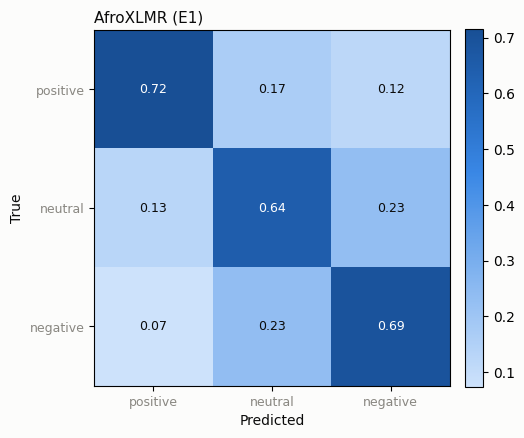

,model,macro_f1,weighted_f1,macro_precision,macro_recall,accuracy
0,AfroXLMR (E1),0.6841,0.6802,0.6842,0.6842,0.6803
1,AfroXLMR (E1) clean,0.6804,0.6766,0.6803,0.6807,0.6767
2,TF-IDF + LogReg,0.6017,0.5981,0.6014,0.6022,0.5984
3,TF-IDF + NaiveBayes,0.5511,0.5532,0.6116,0.5412,0.5556
4,Majority class,0.1846,0.2122,0.1277,0.3333,0.3830


In [30]:
plot_confusion_matrix(m_test["confusion_matrix"], f"AfroXLMR ({BEST})", normalise=True)
plt.show()
comparison_table()

## 7 error analysis

reading a few failures only confirms what you already believed so every guess about
why the model fails is tested by comparing error rates and only the ones the data
supports go in the report

Overall error rate: 0.3197 on 1026 tweets
Overall error rate: 0.3197 on 1026 tweets


,feature,n_with,err_with,err_without,lift
0,has_question,180,0.3333,0.3168,1.05
1,has_emoji,310,0.3129,0.3226,0.97
2,very_short,84,0.2976,0.3217,0.93
3,has_elongation,178,0.2809,0.3278,0.86
4,mentions_only,29,0.2759,0.3210,0.86
5,has_url,303,0.2772,0.3375,0.82
6,has_english,41,0.2439,0.3228,0.76


saved reports/figures/error_features.png


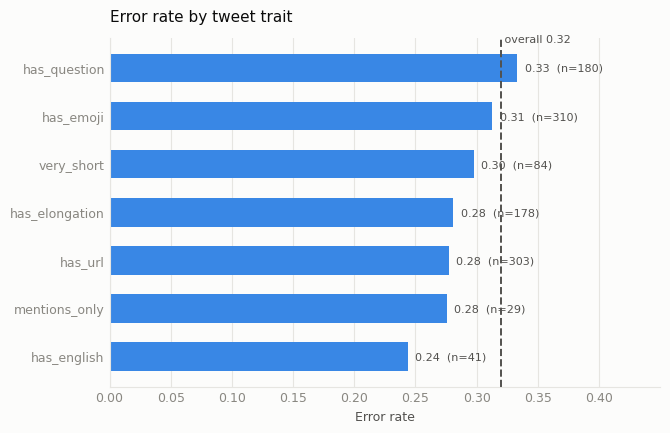

In [31]:
from src import error_analysis as ea

frame = ea.build_frame(splits["test"], test_preds, test_probs, model_name=f"AfroXLMR ({BEST})")
paths = ea.export(frame, f"afroxlmr_{BEST}")

rates = ea.feature_error_rates(frame)
display(rates)
viz.error_feature_chart(rates, 1 - frame["correct"].mean())
plt.show()

In [32]:
print("Which classes get confused with which:")
display(ea.confusion_pairs(frame))

print("\nMost CONFIDENT errors -- what the model has learned wrongly:")
display(frame[~frame["correct"]].nlargest(10, "confidence")[
    ["raw_text", "true_label", "pred_label", "confidence"]])

print("\nMost confident CORRECT predictions -- the 'performs well' examples:")
display(frame[frame["correct"]].nlargest(5, "confidence")[
    ["raw_text", "true_label", "confidence"]])

Which classes get confused with which:


,true_label,pred_label,n,pct_of_errors
0,neutral,negative,90,27.4
1,negative,neutral,83,25.3
2,neutral,positive,50,15.2
3,positive,neutral,46,14.0
4,positive,negative,33,10.1
5,negative,positive,26,7.9



Most CONFIDENT errors -- what the model has learned wrongly:


,raw_text,true_label,pred_label,confidence
372,"#Babyeyi, Konsa umwana wawe neza n'ingenzi, kuko bituma akurana ubudahangarw...",neutral,positive,0.9762
871,Nubwo bamwe bafite inkovu k'umutima Abandi k'umubiri. Duhuza ibitecyerezo. G...,neutral,positive,0.9735
229,@user Mwiriwe neza ndimuhanga nibyiza kuba Aho irubavu baresheje imihigo bag...,neutral,positive,0.9721
245,Niba wumva ushishikajwe niterambere ry'umuhinzi wibirayi dushyigikire ukusho...,neutral,positive,0.9711
23,"Muri iki gitondo, Nsuhuje Abantu mwese muri muri Repubulika Yigenga Ya Kivu....",neutral,positive,0.9693
664,"Imig 3:5 [5]Wiringire Uwiteka n'umutima wawe wose,We kwishingikiriza ku buha...",neutral,positive,0.9683
787,Dushima umuhate mushyira mukurwanya icyi cyorezo dufatanyije byose birashobo...,neutral,positive,0.9675
863,Hanyuma muri ya gahunda yo gushyigikira #Abacu nutekereza Imyambaro ya sipor...,neutral,positive,0.9619
524,Impungenge zishire Ubu wakoresha uruga O’Genius Panda umwana agatsinda neza ...,neutral,positive,0.9606
315,Mubusanzwe kugirango wamuryango mukuru wanjye @user ukugereho neza nuko nawe...,negative,positive,0.9579



Most confident CORRECT predictions -- the 'performs well' examples:


,raw_text,true_label,confidence
768,"Twirinde tutarindishijwe ijisho, ni ukuri tuzatsinda. Maze igihe nkusaba muv...",positive,0.9798
137,"Ubutaha muzatumire n’abaskuti bakuze, duhurire hamwe muri camp. Dutekereze u...",positive,0.9788
476,Rwanda Uri nziza n'abagutuye ni neza Rwanda oyeeee3eeeee @user Kigali Today ...,positive,0.9775
750,"""Umunsi mwiza w'Intwari z'Igihugu """"""""Ubutwari mu banyarwanda. Agaciro Kacu....",positive,0.9773
41,Duharanire kuzasiga umurage mwiza izabera urugero abagera ikirenge mu cyacu ...,positive,0.9768


In [33]:
# where the two models disagree the clearest evidence of what pretraining bought
import numpy as np
base_preds = fitted["TF-IDF + LogReg"].predict(splits["test"]["text"])
base_probs = fitted["TF-IDF + LogReg"].predict_proba(splits["test"]["text"])
base_frame = ea.build_frame(splits["test"], base_preds, base_probs, model_name="TF-IDF + LogReg")

disagree = ea.disagreement(base_frame, frame, "baseline", "transformer")
disagree.to_csv("reports/results/disagreement_baseline_vs_transformer.csv", index=False)
display(disagree.head(12))

winner
transformer    188
baseline       104
neither         40


,raw_text,true_label,pred_baseline,pred_transformer,correct_baseline,correct_transformer,winner
0,@user @user @user Kubeshya ntabwo Ari icyaha uretse iyo urukiko rubyemeje,neutral,negative,neutral,False,True,transformer
1,Abafollowers ba byimbisha intugu ba @user @user nta shati zibakwira babaze w...,negative,neutral,negative,False,True,transformer
2,Hari abantu bahisemo brain kuyikoresha nk’amasogisi mw’iyi minsi😂😂😂,negative,negative,neutral,True,False,baseline
3,@user @user @user Injiji ni wowe. Ikibazo cya mbere n'uko mutimenya!,negative,neutral,negative,False,True,transformer
4,@user @user @user Ariko Mana ubwose ushatse kuvuga iki? Mubyukuri Gusa ndumi...,negative,negative,positive,True,False,baseline
5,@user maze amasaha abiri ntegereje service ..birababaje biteye agahinda,negative,negative,neutral,True,False,baseline
6,"Mbe @user , ko ubanza wananiranye😂😂?",negative,neutral,negative,False,True,transformer
7,Nonese guhita mubyirukakana kuri za WhatsApp status ni uburyo bwo gutangira ...,negative,neutral,negative,False,True,transformer
8,@user @user @user @user @user @user @user @user @user @user @user @user @use...,negative,neutral,negative,False,True,transformer
9,@user Oya nanone abo ubanza biba birenze kuyicinya. Gushyirishamo abandi ni ...,negative,neutral,negative,False,True,transformer


## 8 publish the model

pushes the weights to the hub so the gradio app in `app/` loads them by name the app
holds no weights itself so the space and this notebook run the same model

In [34]:
from huggingface_hub import notebook_login
notebook_login()

In [35]:
HUB_ID = "mbonikevin/afroxlmr-kinyarwanda-sentiment"

trainer.model.push_to_hub(HUB_ID)
tokenizer.push_to_hub(HUB_ID)
print(f"https://huggingface.co/{HUB_ID}")
print("Set MODEL_ID in app/app.py to this, then deploy the Space.")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...0_49eq_/model.safetensors:   0%|          | 13.5kB / 1.11GB            

README.md: 0.00B [00:00, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...k/sentencepiece.bpe.model: 100%|##########| 5.07MB / 5.07MB            

  ...mp_af4k3pk/tokenizer.json: 100%|##########| 17.1MB / 17.1MB            

https://huggingface.co/mbonikevin/afroxlmr-kinyarwanda-sentiment
Set MODEL_ID in app/app.py to this, then deploy the Space.
